In [1]:
import logging
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tabpfn_time_series import (
    TabPFNMode,
    TabPFNTimeSeriesPredictor,
    TimeSeriesDataFrame,
)
from tabpfn_time_series.plot import plot_forecast

from tfmplayground.mouse.evaluation import (
    append_interval_row,
    interval_coverage,
    interval_width,
    mae,
    mape,
    plot_metric,
)
from tfmplayground.mouse.features import (
    Feature,
    add_time_features,
    list_features,
    to_timeseries,
)
from tfmplayground.mouse.preprocessing import (
    COVARIATE_COLUMNS,
    THERAPY_TYPES,
    PreprocessingConfig,
    build_info_df,
    split_context_test,
)
from tfmplayground.mouse.rolling import (
    MIN_CONTEXT,
    append_rolling_interval_rows,
    append_rolling_rows,
    plot_error_by_position,
    plot_mice_rolling,
    plot_mouse_rolling,
    predict_eagle_rolling,
    predict_mouse_rolling,
    predict_tabpfn_rolling,
    rolling_coverage,
    rolling_metrics,
    rolling_width,
    rolling_predictions,
)
from tfmplayground.mouse.context import pool_rows, predict_tabpfn_rolling_with_context
from tfmplayground.mouse import michael, preprocessing

logging.basicConfig(level=logging.INFO, format="%(message)s")

In [2]:
# DATAPATH = preprocessing.RAW_PICKLE_PATH  # "/data/mice/maus.pandas.pkl"
# load_dataset = preprocessing.load_dataset
# config = PreprocessingConfig(
#     trails=[3],
#     roles=[1, 2, 3],
#     min_length=5,
#     max_weight=100,
#     num_animals=4000,
#     num_test_animals=4000,
#     prediction_length=2,
#     include_surgery=False,
#     include_scores=False,
#     seed=None,
# )

DATAPATH = preprocessing.RAW_PICKLE_PATH  # "/data/mice/maus.pandas.pkl"
load_dataset = michael.load_dataset
config = PreprocessingConfig(
    trails=[3],
    roles=[1, 2, 3],
    min_length=5,
    max_weight=100,
    num_animals=4000,
    num_test_animals=4000,
    prediction_length=1,
    seed=None,
)

In [3]:
PREDICTION_LENGTH = config.prediction_length
therapy_types = THERAPY_TYPES
covariate_columns = COVARIATE_COLUMNS

# Time features, see list_features() for all options
FEATURES = [
    Feature.RUNNING_INDEX,
    Feature.DAYS_SINCE,
    Feature.SEASONAL
]
# With the previous weight, so other mice can teach the change from one visit to the next,
# and the treatment flag of each visit
FEATURES_LAG = [*FEATURES, Feature.LAG, Feature.INTERVENTION]

# Eagle-eye: mice fitted in parallel, one fit takes about 1.5 min
N_JOBS = 16
logging.getLogger("pymc").setLevel(logging.WARNING)
logging.getLogger("arviz").setLevel(logging.WARNING)

# Rolling evaluation
EVERY = 1  # predict every k-th measurement, the last one is always included
EAGLE_CACHE = "/data/PFN/Mouse/rolling/eagle_trail3.parquet"  # new path when data or sampler settings change
TABPFN_CACHE = "/data/PFN/Mouse/rolling/tabpfn_trail3.parquet"  # new path when data, FEATURES or TabPFN change
TABPFN_LAG_CACHE = "/data/PFN/Mouse/rolling/tabpfn_lag_int_trail3.parquet"  # FEATURES_LAG
# FEATURES_LAG plus the other trail-3 mice up to the forecast origin date as context: new path when the pool changes as well
TABPFN_CTX_CACHE = "/data/PFN/Mouse/rolling/tabpfn_lag_int_ctx_causal_trail3.parquet"
# Same, but only pool mice with the therapy type (role) of the predicted mouse
TABPFN_ROLE_CTX_CACHE = "/data/PFN/Mouse/rolling/tabpfn_lag_int_rolectx_causal_trail3.parquet"

os.environ["SETUPTOOLS_USE_DISTUTILS"] = "local"
os.environ["TABPFN_TOKEN"] = "tabpfn_sk_3XA36olToOXSzenBDBSzotxkWIoad2auFJauzRmtfjI"

In [4]:
# Results tables, every model section appends its rows
RESULT_COLUMNS = ["Model", *THERAPY_TYPES.values(), "Overall"]
table_mae = pd.DataFrame(columns=RESULT_COLUMNS)
table_mape = pd.DataFrame(columns=RESULT_COLUMNS)
# Fraction of ground truths inside the 90% interval (per mouse, averaged over mice)
table_coverage = pd.DataFrame(columns=RESULT_COLUMNS)
# Mean width (g) of that interval, averaged in the same way
table_width = pd.DataFrame(columns=RESULT_COLUMNS)

## Prepare data

### Read data

In [5]:
df = load_dataset(DATAPATH, config)
info_df = build_info_df(df)

df

Animals: 188 -> 186 after filtering -> 186 sampled


,item_id,timestamp,time,target,radio,chemo,intervention,trail,role
0,3,2013-08-05,13:00:00,32.5,0,0,0,3,1
1,3,2013-08-09,13:00:00,28.9,0,0,0,3,1
2,3,2013-08-13,13:30:00,29.0,0,0,0,3,1
3,3,2013-08-14,08:00:00,29.5,0,0,0,3,1
4,3,2013-08-19,08:39:00,29.4,0,0,0,3,1
...,...,...,...,...,...,...,...,...,...
3044,437,2016-06-16,08:14:00,16.7,0,0,0,3,1
3045,437,2016-06-17,07:51:00,16.8,0,0,0,3,1
3046,437,2016-06-18,11:44:00,16.9,0,0,0,3,1
3047,437,2016-06-19,14:12:00,16.6,0,0,0,3,1


### Preprocess data

In [6]:
context_df, future_df, test_df = split_context_test(df, config)

context_tsdf, future_tsdf = to_timeseries(context_df, future_df)
train_tsdf, test_tsdf = add_time_features(context_tsdf, future_tsdf, FEATURES)

In [7]:
# Pool of context mice: all loaded (trail-3) mice, time features computed per mouse.
# Every forecast origin of mouse m sees the other mice, marked with is_target = 0, but only their
# measurements up to the date of its own last measurement (features recomputed on that cut).
# POOL is the uncut view over the full lives, for inspection only.
POOL = pool_rows(df, FEATURES_LAG)

POOL

,mouse_id,timestamp,target,running_index,days_since,sin_#0,cos_#0,sin_#1,cos_#1,sin_#2,cos_#2,lag_1,days_since_lag,intervention_flag,role
0,3,2013-08-05,32.5,0,0,0.000000e+00,1.000000e+00,0.000000e+00,1.0,0.000000e+00,1.000000e+00,NaN,NaN,0,1
1,3,2013-08-09,28.9,1,4,5.000000e-01,8.660254e-01,1.224647e-16,-1.0,1.000000e+00,6.123234e-17,32.5,4.0,0,1
2,3,2013-08-13,29.0,2,8,8.660254e-01,5.000000e-01,-2.449294e-16,1.0,1.224647e-16,-1.000000e+00,28.9,4.0,0,1
3,3,2013-08-14,29.5,3,9,1.000000e+00,6.123234e-17,3.673940e-16,-1.0,-1.000000e+00,-1.836970e-16,29.0,1.0,0,1
4,3,2013-08-19,29.4,4,14,8.660254e-01,-5.000000e-01,-4.898587e-16,1.0,-2.449294e-16,1.000000e+00,29.5,5.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3044,437,2016-06-16,16.7,26,38,-7.431448e-01,6.691306e-01,-8.660254e-01,-0.5,9.510565e-01,3.090170e-01,16.3,1.0,0,1
3045,437,2016-06-17,16.8,27,39,-5.877853e-01,8.090170e-01,-2.204364e-15,1.0,5.877853e-01,-8.090170e-01,16.7,1.0,0,1
3046,437,2016-06-18,16.9,28,40,-4.067366e-01,9.135455e-01,8.660254e-01,-0.5,-5.877853e-01,-8.090170e-01,16.8,1.0,0,1
3047,437,2016-06-19,16.6,29,41,-2.079117e-01,9.781476e-01,-8.660254e-01,-0.5,-9.510565e-01,3.090170e-01,16.9,1.0,0,1


In [8]:
train_tsdf

target   id  intervention  running_index  days_since  \
item_id timestamp                                                          
3       2013-08-05    32.5    3             0              0           0   
        2013-08-09    28.9    3             0              1           4   
        2013-08-13    29.0    3             0              2           8   
        2013-08-14    29.5    3             0              3           9   
        2013-08-19    29.4    3             0              4          14   
...                    ...  ...           ...            ...         ...   
437     2016-06-15    16.3  437             0             25          37   
        2016-06-16    16.7  437             0             26          38   
        2016-06-17    16.8  437             0             27          39   
        2016-06-18    16.9  437             0             28          40   
        2016-06-19    16.6  437             0             29          41   

                      sin_#0        cos_#0        sin_#1  cos_#1  \
item_id timestamp                                                  
3       2013-08-05  0.000000  1.000000e+00  0.000000e+00     1.0   
        2013-08-09  0.500000  8.660254e-01  1.224647e-16    -1.0   
        2013-08-13  0.866025  5.000000e-01 -2.449294e-16     1.0   
        2013-08-14  1.000000  6.123234e-17  3.673940e-16    -1.0   
        2013-08-19  0.866025 -5.000000e-01 -4.898587e-16     1.0   
...                      ...           ...           ...     ...   
437     2016-06-15 -0.866025  5.000000e-01  8.660254e-01    -0.5   
        2016-06-16 -0.743145  6.691306e-01 -8.660254e-01    -0.5   
        2016-06-17 -0.587785  8.090170e-01 -2.204364e-15     1.0   
        2016-06-18 -0.406737  9.135455e-01  8.660254e-01    -0.5   
        2016-06-19 -0.207912  9.781476e-01 -8.660254e-01    -0.5   

                          sin_#2        cos_#2  
item_id timestamp                               
3       2013-08-05  0.000000e+00  1.000000e+00  
        2013-08-09  1.000000e+00  6.123234e-17  
        2013-08-13  1.224647e-16 -1.000000e+00  
        2013-08-14 -1.000000e+00 -1.836970e-16  
        2013-08-19 -2.449294e-16  1.000000e+00  
...                          ...           ...  
437     2016-06-15 -1.224647e-15  1.000000e+00  
        2016-06-16  9.510565e-01  3.090170e-01  
        2016-06-17  5.877853e-01 -8.090170e-01  
        2016-06-18 -5.877853e-01 -8.090170e-01  
        2016-06-19 -9.510565e-01  3.090170e-01  

[2863 rows x 11 columns]

## Analysis

### Rolling evaluation (full life)
Every measurement from the 3rd on is predicted one step ahead from all earlier weights of the same mouse (expanding window), instead of only the last one. TabPFN and Eagle-eye predict exactly the same points. The context starts at `MIN_CONTEXT = 2` measurements, because TabPFN cannot fit on a single row (and Eagle-eye only returns its prior then). The trail-context models only see the measurements of the other mice up to the date of the forecast origin (the last own measurement), so no data from future days reaches the context.

Eagle-eye is refitted for every point. The forecasts of both models are cached (`EAGLE_CACHE`, `TABPFN_CACHE`), and a rerun continues where it stopped, so a single mouse that has already been predicted is reused by the run over all mice. Set `USE_EAGLE_CACHE` or `USE_TABPFN_CACHE` to `False` to predict again; the new forecasts overwrite the cached ones. For a quick run, use `FRACTION < 1` (a fixed random subset of the mice), `EVERY > 1` or fewer `draws`/`chains` (with a different cache path). `EVERY`, the cache paths and `N_JOBS` are in the initialization at the top.

In [9]:
FRACTION = 1.0  # fraction of the mice in the rolling evaluation, < 1 for a quick test
USE_TABPFN_CACHE = True  # False: predict again and overwrite the cached TabPFN forecasts
USE_EAGLE_CACHE = True  # False: refit Eagle-eye and overwrite the cached forecasts
USE_TABPFN_LAG_CACHE = True  # False: predict again and overwrite the cached forecasts with the lag
USE_TABPFN_CTX_CACHE = True  # False: predict again and overwrite the cached forecasts with trail context
USE_TABPFN_ROLE_CTX_CACHE = True  # same, for the context of the same therapy type only

# Models of the rolling evaluation
tabpfn_rolling_reg = TabPFNTimeSeriesPredictor(tabpfn_mode=TabPFNMode.LOCAL)
rolling_predictors = {
    "TabPFN": lambda c, t: predict_tabpfn_rolling(
        c, t, tabpfn_rolling_reg, FEATURES, cache_path=TABPFN_CACHE, use_cache=USE_TABPFN_CACHE
    ),
    # "TabPFN + lag + intervention": lambda c, t: predict_tabpfn_rolling(
    #     c, t, tabpfn_rolling_reg, FEATURES_LAG, cache_path=TABPFN_LAG_CACHE, use_cache=USE_TABPFN_LAG_CACHE
    # ),
    "TabPFN + context": lambda c, t: predict_tabpfn_rolling_with_context(
        c, t, df, tabpfn_rolling_reg, FEATURES_LAG, cache_path=TABPFN_CTX_CACHE, use_cache=USE_TABPFN_CTX_CACHE
    ),
    # "TabPFN + lag + intervention + same-therapy context": lambda c, t: predict_tabpfn_rolling_with_context(
    #     c, t, df, tabpfn_rolling_reg, FEATURES_LAG, cache_path=TABPFN_ROLE_CTX_CACHE,
    #     use_cache=USE_TABPFN_ROLE_CTX_CACHE, same_role=True,
    # ),
    "Eagle-eye": lambda c, t: predict_eagle_rolling(
        c, t, n_jobs=N_JOBS, cache_path=EAGLE_CACHE, use_cache=USE_EAGLE_CACHE
    ),
}

#### Single random mouse
Predicts the whole life of one random mouse, which takes a few minutes. Set `mouse_id` by hand to look at a specific mouse.

In [10]:
mouse_id = np.random.choice(df["item_id"].unique())

mouse_df = predict_mouse_rolling(mouse_id, df, rolling_predictors, min_context=MIN_CONTEXT, every=EVERY)
mouse_df

1 mice -> 10 forecast origins
TabPFN: 10 origins cached, 0 to predict
TabPFN + context: 10 origins cached, 0 to predict
Eagle-eye: 10 origins cached, 0 to predict


,model,mouse_id,step,timestamp,days_since,days_before_death,steps_before_death,role,truth,prediction,q05,q95,ae,ape
0,Eagle-eye,148,2,2013-11-11,13,28,9,1,21.7,20.234021,13.974432,26.633850,1.465979,0.067557
1,Eagle-eye,148,3,2013-11-17,19,22,8,1,20.8,20.776678,16.081336,24.997157,0.023322,0.001121
2,Eagle-eye,148,4,2013-11-24,26,15,7,1,22.2,20.295691,16.730142,23.446908,1.904309,0.085780
3,Eagle-eye,148,5,2013-12-01,33,8,6,1,21.4,21.329026,17.846440,24.394232,0.070974,0.003317
4,Eagle-eye,148,6,2013-12-02,34,7,5,1,21.1,21.196552,18.545594,23.649818,0.096552,0.004576
5,Eagle-eye,148,7,2013-12-03,35,6,4,1,21.0,21.014036,18.810296,23.041954,0.014036,0.000668
6,Eagle-eye,148,8,2013-12-04,36,5,3,1,20.6,20.905982,19.214903,22.524240,0.305982,0.014853
7,Eagle-eye,148,9,2013-12-05,37,4,2,1,19.9,20.621573,19.137931,22.027722,0.721573,0.036260
8,Eagle-eye,148,10,2013-12-06,38,3,1,1,19.9,20.058066,18.647130,21.391327,0.158066,0.007943
9,Eagle-eye,148,11,2013-12-09,41,0,0,1,16.1,19.875755,18.612608,21.098043,3.775755,0.234519


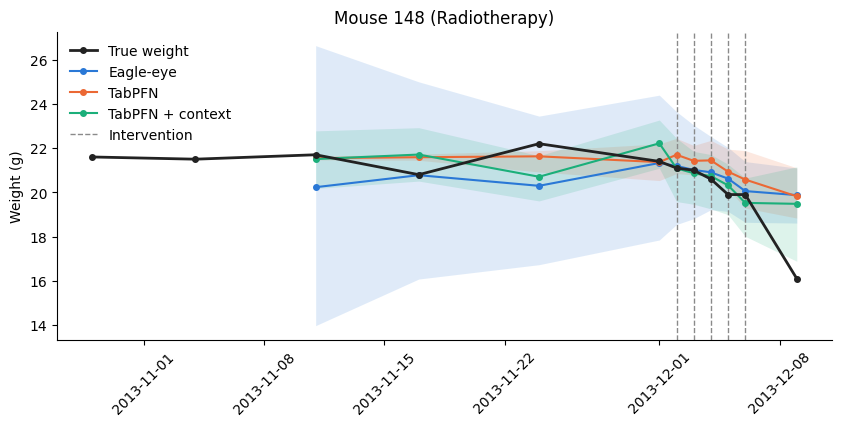

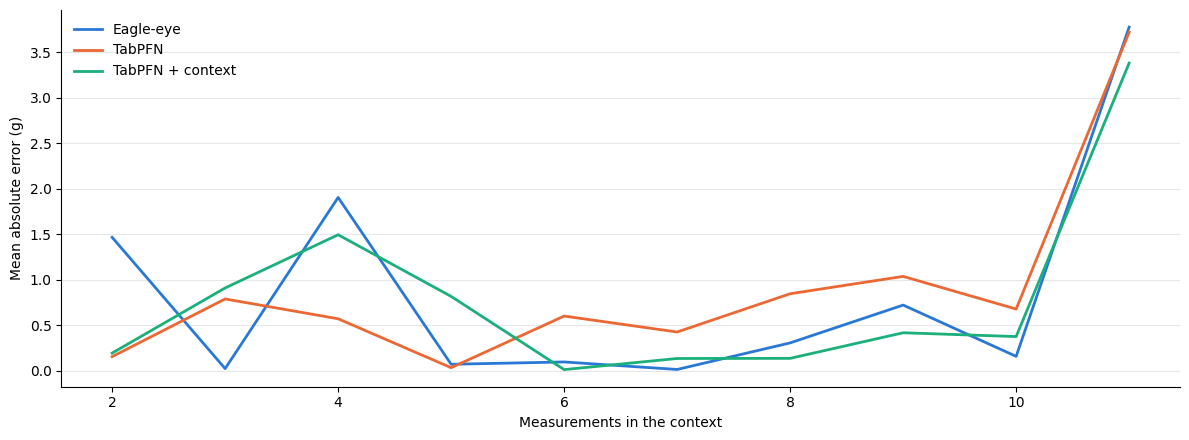

role,Radiotherapy,Overall
model,,
Eagle-eye,0.9,0.9
TabPFN,0.4,0.4
TabPFN + context,0.8,0.8


role,Radiotherapy,Overall
model,,
Eagle-eye,5.560444,5.560444
TabPFN,1.429451,1.429451
TabPFN + context,2.612572,2.612572


n       MAE      MAPE
model            role                                
Eagle-eye        Overall       10  0.853655  0.045659
                 Radiotherapy  10  0.853655  0.045659
TabPFN           Overall       10  0.885512  0.047937
                 Radiotherapy  10  0.885512  0.047937
TabPFN + context Overall       10  0.787133  0.042158
                 Radiotherapy  10  0.787133  0.042158

In [11]:
plot_mouse_rolling(mouse_df, df, mouse_id)
plt.legend(frameon=False)
plt.show()

plot_error_by_position(mouse_df, x="step", min_count=1)
plt.show()

display(rolling_coverage(mouse_df))
display(rolling_width(mouse_df))
rolling_metrics(mouse_df)

#### All mice
About 3000 prediction points. TabPFN takes about 1 h, Eagle-eye several hours with 16 jobs (both resumable via their caches). `FRACTION` limits the run to a part of the mice. The results are added to the MAE and MAPE tables as "(rolling)" rows.

In [12]:
long_df = rolling_predictions(df, rolling_predictors, min_context=MIN_CONTEXT, every=EVERY, fraction=FRACTION)
long_df

186 mice -> 2677 forecast origins
TabPFN: 2677 origins cached, 0 to predict
TabPFN + context: 2677 origins cached, 0 to predict
Eagle-eye: 2677 origins cached, 0 to predict


,model,mouse_id,step,timestamp,days_since,days_before_death,steps_before_death,role,truth,prediction,q05,q95,ae,ape
0,Eagle-eye,3,2,2013-08-13,8,83,22,1,29.0,33.031892,21.356092,45.945871,4.031892,0.139031
1,Eagle-eye,3,3,2013-08-14,9,82,21,1,29.5,31.243582,22.732804,40.420026,1.743582,0.059104
2,Eagle-eye,3,4,2013-08-19,14,77,20,1,29.4,30.999278,23.340807,39.084099,1.599278,0.054397
3,Eagle-eye,3,5,2013-08-26,21,70,19,1,29.7,30.613573,23.860440,37.677798,0.913573,0.030760
4,Eagle-eye,3,6,2013-09-02,28,63,18,1,28.6,30.557657,24.349839,37.038850,1.957657,0.068450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8026,TabPFN + context,437,26,2016-06-16,38,4,4,1,16.7,16.247717,14.964210,17.708183,0.452283,0.027083
8027,TabPFN + context,437,27,2016-06-17,39,3,3,1,16.8,16.663200,15.454243,17.916296,0.136800,0.008143
8028,TabPFN + context,437,28,2016-06-18,40,2,2,1,16.9,16.793232,15.710085,17.915298,0.106768,0.006318
8029,TabPFN + context,437,29,2016-06-19,41,1,1,1,16.6,16.981184,16.014320,17.999636,0.381184,0.022963


In [13]:
table_mae, table_mape = append_rolling_rows(long_df, table_mae, table_mape)
table_coverage, table_width = append_rolling_interval_rows(long_df, table_coverage, table_width)

# Coverage of the 90% interval, closest to 0.9 first
display(rolling_coverage(long_df).sort_values("Overall", key=lambda x: (x - 0.9).abs()))
# Mean width (g) of the 90% interval, narrowest first
display(rolling_width(long_df).sort_values("Overall"))
# Models ordered by overall MAE
metrics = rolling_metrics(long_df)
model_order = metrics.xs("Overall", level="role")["MAE"].sort_values().index
metrics.reindex(model_order, level="model")

role,Radiotherapy,Radio- and chemotherapy,Chemotherapy,Overall
model,,,,
TabPFN + context,0.901431,0.888731,0.902022,0.897503
Eagle-eye,0.896593,0.897493,0.890338,0.895101
TabPFN,0.705260,0.634895,0.669038,0.672240


role,Radiotherapy,Radio- and chemotherapy,Chemotherapy,Overall
model,,,,
TabPFN,2.358758,2.841807,2.374654,2.519109
TabPFN + context,2.910424,3.327080,3.148120,3.112560
Eagle-eye,5.013986,6.561627,5.490731,5.649072


n       MAE      MAPE
model            role                                             
TabPFN + context Chemotherapy              662  0.699388  0.028302
                 Overall                  2677  0.691224  0.028354
                 Radio- and chemotherapy   717  0.816416  0.033442
                 Radiotherapy             1298  0.557869  0.023319
TabPFN           Chemotherapy              662  0.735499  0.029640
                 Overall                  2677  0.737300  0.030178
                 Radio- and chemotherapy   717  0.884864  0.036054
                 Radiotherapy             1298  0.591536  0.024839
Eagle-eye        Chemotherapy              662  1.018976  0.040706
                 Overall                  2677  1.045338  0.041737
                 Radio- and chemotherapy   717  1.365667  0.053665
                 Radiotherapy             1298  0.751371  0.030841

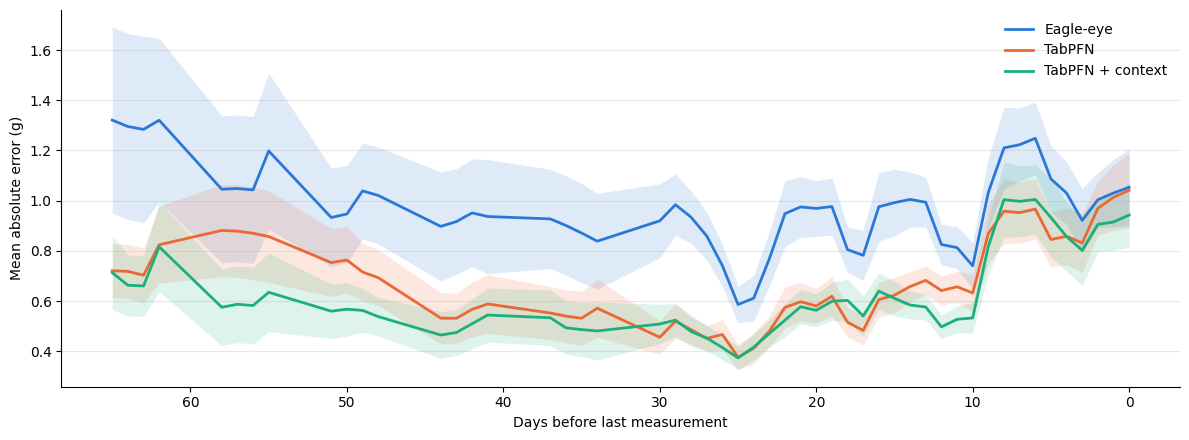

In [14]:
plot_error_by_position(long_df, x="days_before_death", window=4, min_count=50, show_counts=False)
plt.show()

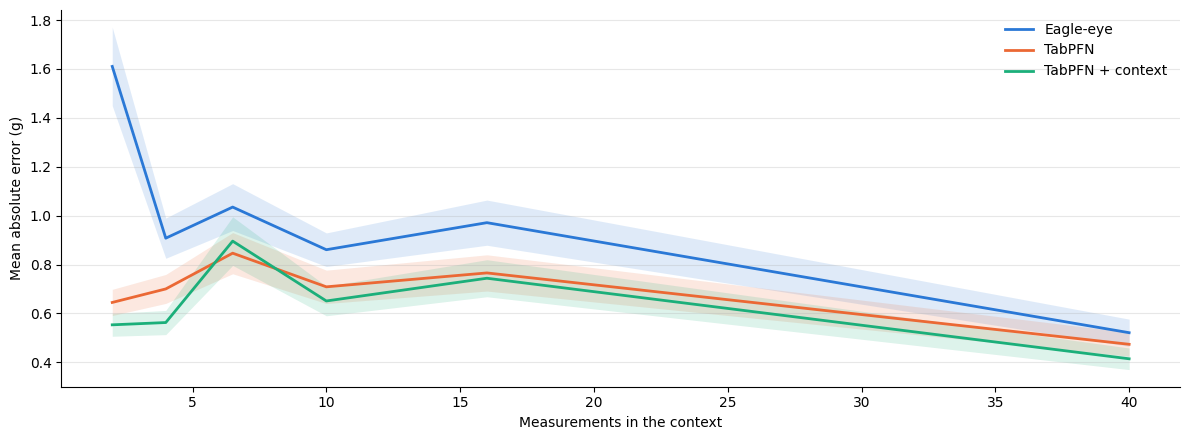

In [15]:
# The trail context should help most for short own contexts (small step)
plot_error_by_position(long_df, x="step", bins=[1, 3, 5, 8, 12, 20, 60], min_count=20, show_counts=False)
plt.show()

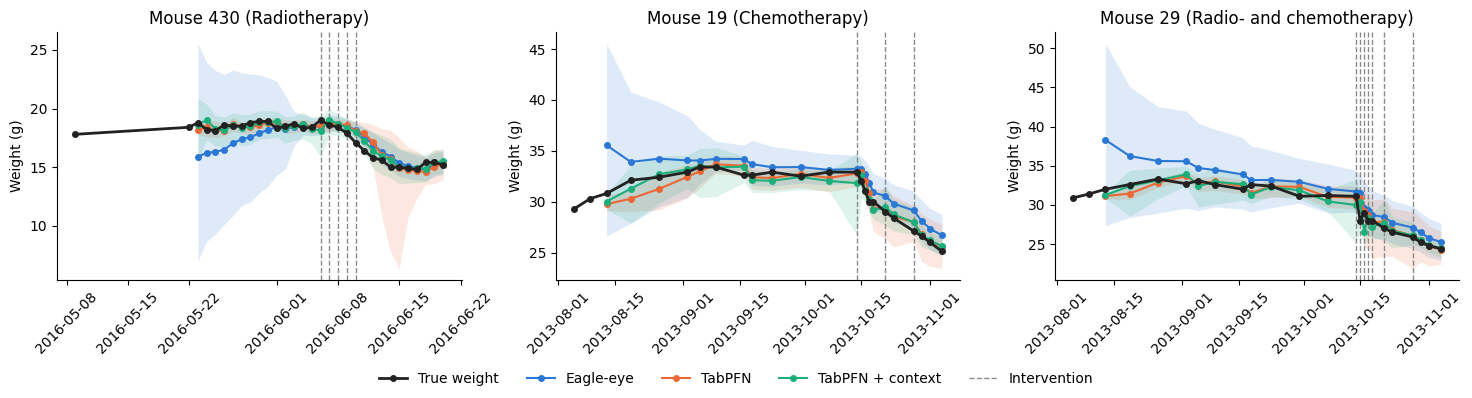

In [19]:
# One random mouse with at least 20 measurements per therapy type: radiotherapy, chemotherapy, radio- and chemotherapy
mouse_roles = long_df.groupby("mouse_id")["role"].first()
n_measurements = df["item_id"].value_counts()
mouse_roles = mouse_roles[n_measurements.reindex(mouse_roles.index) >= 20]
plot_mouse_ids = [np.random.choice(mouse_roles.index[mouse_roles == role]) for role in [1, 3, 2]]
plot_mice_rolling(long_df, df, plot_mouse_ids)
plt.show()

### Comparison

,Model,No treatment,Radiotherapy,Radio- and chemotherapy,Chemotherapy,Surgery,Overall
0,TabPFN + context (rolling),NaN,0.901431,0.888731,0.902022,NaN,0.897503
1,Eagle-eye (rolling),NaN,0.896593,0.897493,0.890338,NaN,0.895101
2,TabPFN (rolling),NaN,0.705260,0.634895,0.669038,NaN,0.672240


,Model,No treatment,Radiotherapy,Radio- and chemotherapy,Chemotherapy,Surgery,Overall
0,TabPFN (rolling),NaN,2.358758,2.841807,2.374654,NaN,2.519109
1,TabPFN + context (rolling),NaN,2.910424,3.327080,3.148120,NaN,3.112560
2,Eagle-eye (rolling),NaN,5.013986,6.561627,5.490731,NaN,5.649072


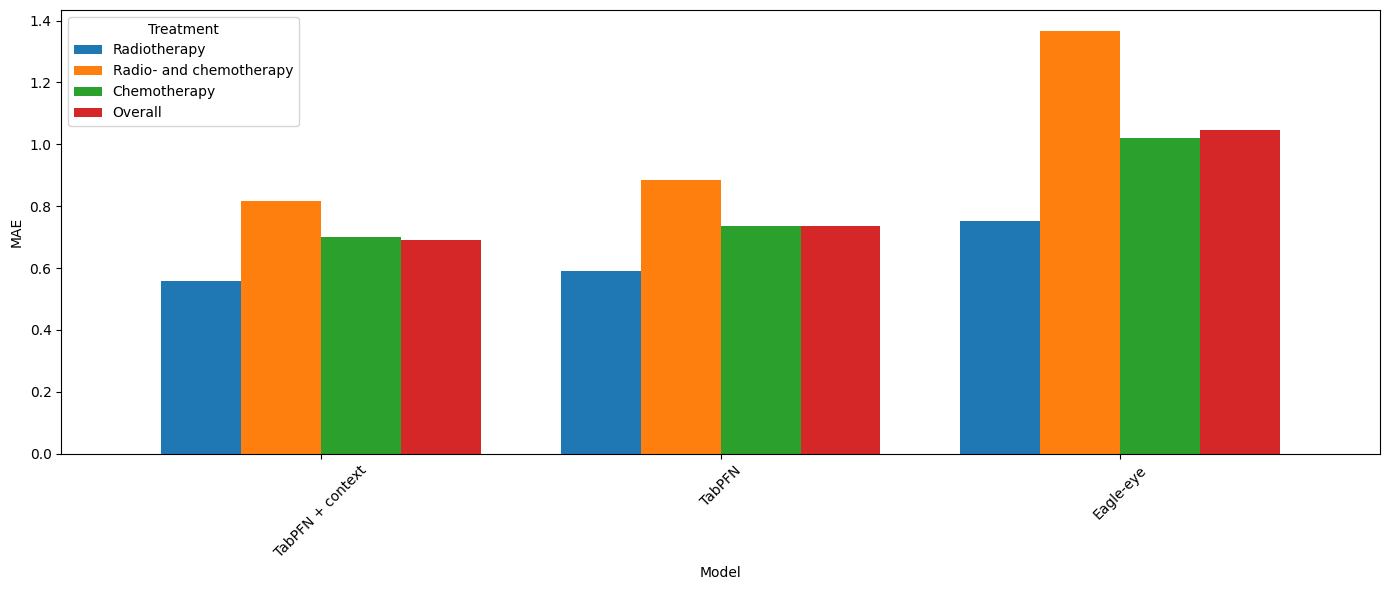

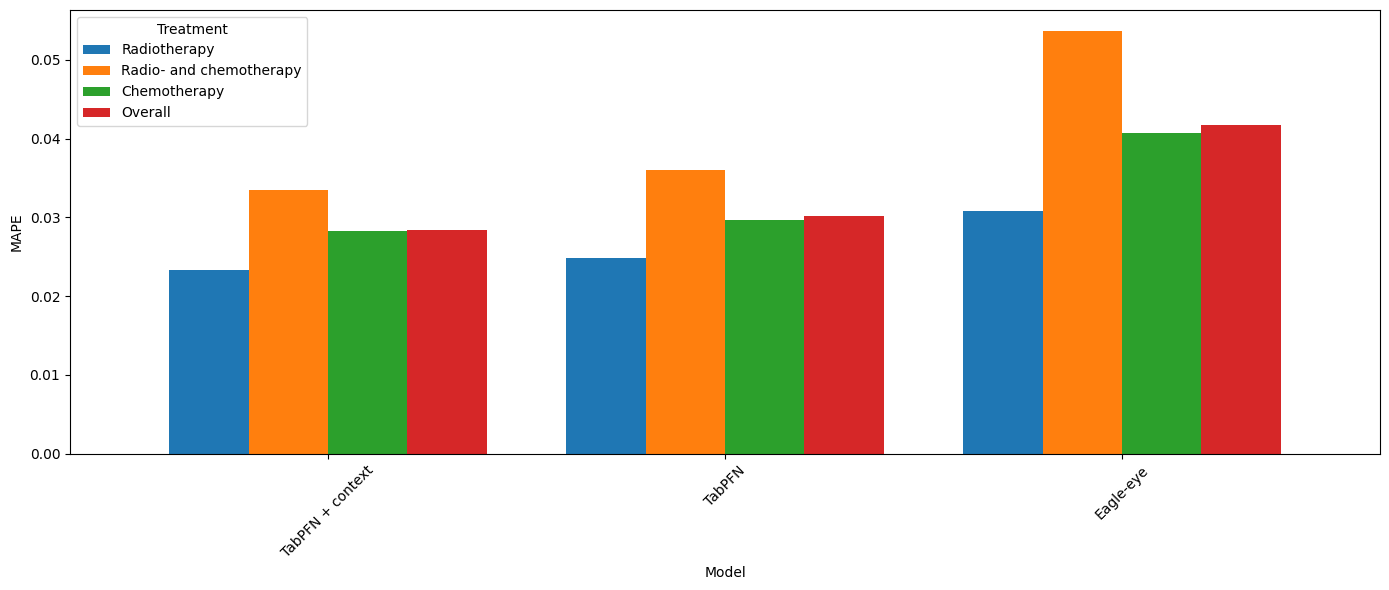

In [17]:
table_mae.sort_values("Overall").reset_index()
table_mape.sort_values("Overall").reset_index()

# Coverage of the 90% interval, closest to 0.9 first
display(table_coverage.sort_values("Overall", key=lambda x: (x - 0.9).abs()).reset_index(drop=True))
# Mean width (g) of the 90% interval, a higher coverage from a wider interval is no surprise
display(table_width.sort_values("Overall").reset_index(drop=True))

# MAE plot
plot_metric(table_mae, "MAE")

# MAPE plot
plot_metric(table_mape, "MAPE")

plt.show()